# Eigenfaces with PCA

Principal component analysis on 400 face photos. Each 64×64 image has 4,096 pixels. PCA squeezes it into 20 numbers, rebuilds the face from them, and shows what those numbers capture: the main ways faces differ from the average face.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces

## Load the dataset

The Olivetti faces: 400 grayscale photos of 40 people, 10 photos each. Every row is one face, with 4,096 pixel values (64×64) and a `target` column holding the person ID.

In [2]:
data = fetch_olivetti_faces(shuffle=False)
faces = pd.DataFrame(data.data)
faces['target'] = data.target
print(faces.shape)

(400, 4097)


## Plot the faces

A helper that arranges rows of pixel data into a grid of images, then the first 40 faces. `X` holds the pixels and `y` the person ID.

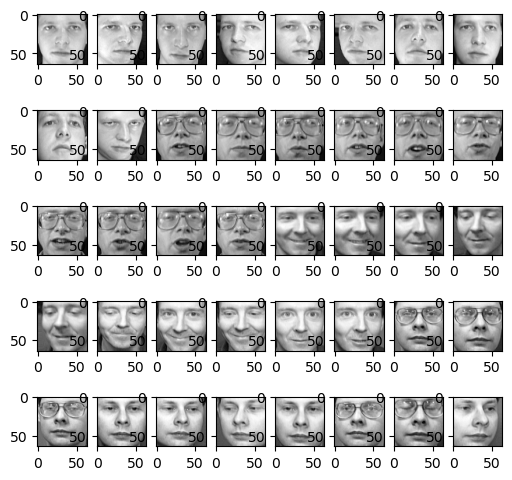

In [3]:
def plot_faces(pixels, nRows,nCols):
    fig, axes = plt.subplots(nRows, nCols, figsize=(6, 6))
    for i, ax in enumerate(axes.flat):
        ax.imshow(np.array(pixels)[i].reshape(64, 64), cmap='gray')
    plt.show()

# Prepare the data
X = faces.drop('target', axis=1)
y = faces['target']

# display the first nRows*nCols of faces in the dataset
plot_faces(X, 5, 8)

## The mean face

The average of all 400 faces. PCA describes every face as this mean plus a weighted sum of a few directions of variation.

(4096,)


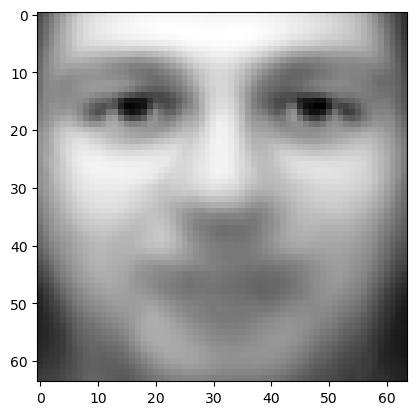

In [4]:
mean_X = X.mean(axis=0)
print(mean_X.shape)
faceplot = plt.imshow(np.array(mean_X).reshape(64, 64), cmap='gray')

## Center the data

Subtracting the mean face from every face leaves only what makes each one different.

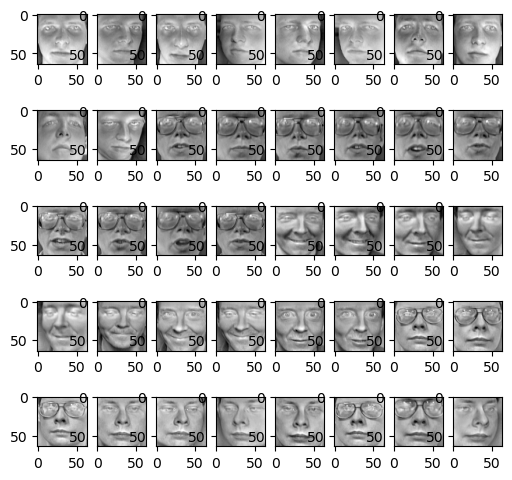

In [5]:
zeromean_X = X - mean_X
plot_faces(zeromean_X, 5, 8)

## Apply PCA with 20 components

Each face goes from 4,096 pixel values to a 20-number weight vector. The input is centered but not scaled.

In [6]:
from sklearn.decomposition import PCA

# reduce to 20 dimensional weight vector to represent each face; dimension reduction from 4096 to 20; input to PCA is centered but not scaled
pca = PCA(n_components=20)
pca.fit(zeromean_X)

PCA(n_components=20)

In [7]:
print(f'Variance explained by 20 components: {pca.explained_variance_ratio_.sum():.1%}')
print(f'First component alone: {pca.explained_variance_ratio_[0]:.1%}')

Variance explained by 20 components: 76.3%
First component alone: 23.8%


## Eigenfaces

The principal components, drawn as images. Each is a direction of variation across the faces.

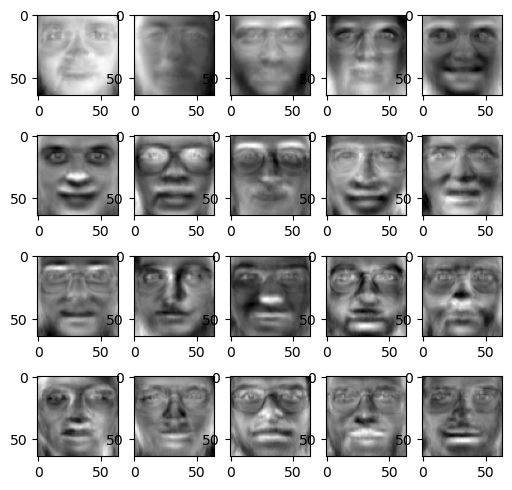

In [8]:
eigenfaces = pca.components_
plot_faces(eigenfaces, 4, 5)

## Transform the data

Every face is now a 20-dimensional weight vector instead of 4,096 raw pixel values.

In [9]:
zeromean_X_pca = pca.transform(zeromean_X)
print(zeromean_X_pca.shape)

(400, 20)


## Reconstruct the faces

Multiplying the weights by the eigenfaces and adding the mean face back gives an approximation of each original.

(20, 4096)
(400, 20)


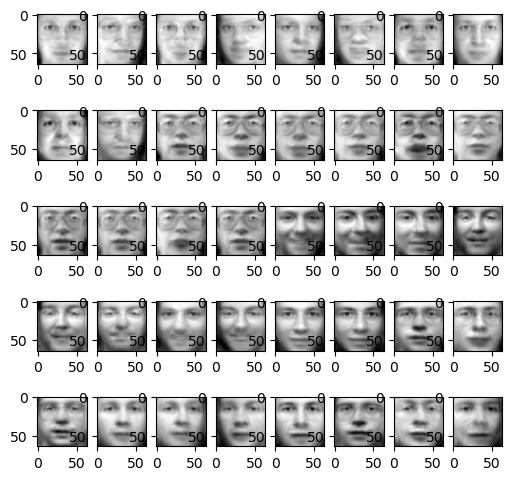

In [10]:
print(eigenfaces.shape)
print(zeromean_X_pca.shape)

reconstructed_zeromean_X = np.matmul(zeromean_X_pca, eigenfaces)
mean_matrix = np.tile(mean_X, (400,1))
reconstructed_X = reconstructed_zeromean_X + mean_matrix
plot_faces(reconstructed_X, 5, 8)

## Reconstruction error

The difference between each original face and its reconstruction with 20 components.

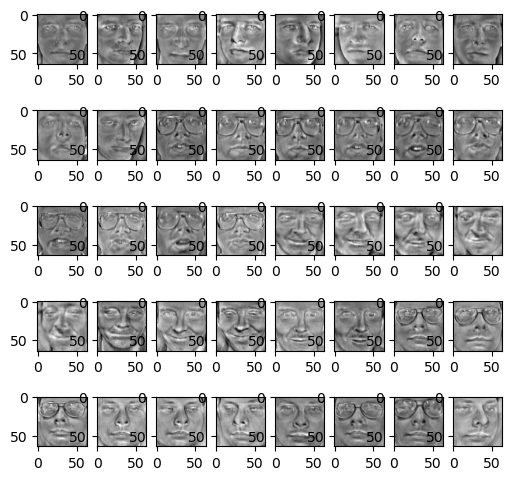

In [11]:
diff = X - reconstructed_X
plot_faces(diff, 5, 8)

The largest L2 norm of those differences across all 400 faces:

In [12]:
diff_norm = np.linalg.norm(diff, axis=1)
print(np.max(diff_norm))

6.25345


## Repeat with 150 components

More components recover more detail, so the largest error drops.

In [13]:
pca_150 = PCA(n_components=150)
pca_150.fit(zeromean_X)
zeromean_X_pca_150 = pca_150.transform(zeromean_X)

reconstructed_zeromean_X_150 = pca_150.inverse_transform(zeromean_X_pca_150)
reconstructed_X_150 = reconstructed_zeromean_X_150 + mean_matrix
diff_150 = X - reconstructed_X_150
diff_norm_150 = np.linalg.norm(diff_150, axis=1)
print("Maximum L2-norm of differences (150 components):", np.max(diff_norm_150))

Maximum L2-norm of differences (150 components): 2.0983245


## Walking along an eigenface

Starting from the mean face and moving along one eigenface in five steps, from two steps down to two steps up, shows what that direction encodes.

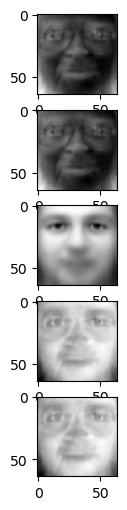

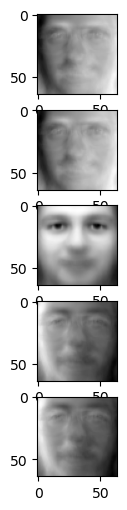

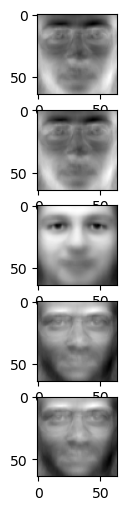

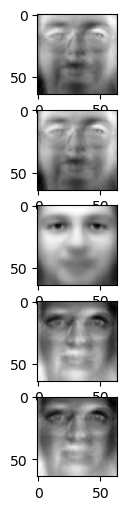

In [14]:
def visualize_eigenface_direction(eigenface_ID):
    face = eigenfaces[eigenface_ID]
    s = pca.singular_values_[eigenface_ID]
    s_row = np.ones(4096) * s

    f0 = np.array(mean_X) - np.array(face) * np.array(2 * s_row)
    f1 = np.array(mean_X) - np.array(face) * np.array(s_row)
    f2 = np.array(mean_X)
    f3 = np.array(mean_X) + np.array(face) * np.array(s_row)
    f4 = np.array(mean_X) + np.array(face) * np.array(2 * s_row)

    f = np.vstack((f0.T, f1.T, f2.T, f3.T, f4.T))
    plot_faces(f, 5, 1)

# Visualize variations along the first four eigenfaces
visualize_eigenface_direction(0)
visualize_eigenface_direction(1)
visualize_eigenface_direction(2)
visualize_eigenface_direction(3)